# XGBoost — GAT IOP Prediction

This notebook develops a Gradient Boosted Tree model (XGBoost) to predict Applanation/GAT IOP from:

- iCare IOP
- Central Corneal Thickness (CCT)

It uses the same patient-level train / validation / test splits as the Random Forest and ANN notebooks, so the three models can be compared fairly.

The test set remains untouched until the final evaluation section.

## What this notebook finds

Stated up front so the experiments below can be read with the destination in mind.

- **Test MAE 2.901 mmHg, RMSE 3.986, R² 0.730** — the best result in the project.
- **That is 0.10 mmHg better than a two-parameter straight line** fitted on iCare alone, and 0.31 mmHg better than using the iCare reading unchanged.
- **CCT contributes nothing measurable.** Permutation importance, an ablation, and the linear baselines all agree. The 480–580 µm range filter in the cleaning pipeline is the likely cause and is testable.
- **Above 30 mmHg the model performs worse than the raw iCare reading**, and systematically under-predicts, because 93% of training eyes sit below 30 mmHg.
- **Random Forest, XGBoost and the ANN agree within 0.04 mmHg**, which suggests the limit is the data rather than the algorithm.

### Why XGBoost after Random Forest

Random Forest and XGBoost are both tree ensembles, but they build the ensemble differently:

- **Random Forest** grows many deep trees independently on bootstrap samples and *averages* them. It reduces variance.
- **XGBoost** grows shallow trees *sequentially*, where each new tree is fitted to the residual error left by the trees before it. It reduces bias, and controls variance through a learning rate and explicit regularization.

For a small-feature, moderately-sized tabular problem like this one, boosting usually matches or slightly beats bagging, and it gives us finer control over the bias/variance trade-off.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import xgboost as xgb

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("xgboost:", xgb.__version__)

xgboost: 3.4.1


## Load Dataset

The same splits produced by `src/split_dataset.py` are used here.

In [2]:
train = pd.read_csv("../data/splits/train.csv")
validation = pd.read_csv("../data/splits/validation.csv")
test = pd.read_csv("../data/splits/test.csv")

print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

Train: (4648, 5)
Validation: (1001, 5)
Test: (990, 5)


## Features, Target and Patient Groups

Features and target are the same as the other notebooks.

In addition we derive the **patient UID** from the EUID (`L00220` → `00220`). The UID is *not* a model feature. It is needed for cross-validation: the two eyes of one patient are highly correlated, so they must never be split across a CV fold boundary, for exactly the same reason they are never split across train/test.

In [3]:
features = ["icare_iop", "cct"]
target = "applanation_iop"

X_train = train[features]
y_train = train[target]

X_validation = validation[features]
y_validation = validation[target]

X_test = test[features]
y_test = test[target]

# Patient-level grouping for cross-validation (NOT a feature)
train_groups = train["euid"].str[1:]

print("Training rows:", len(X_train))
print("Training patients:", train_groups.nunique())

Training rows: 4648
Training patients: 2536


## Evaluation Helper

Every model in this notebook is scored with the same three metrics:

- **MAE** — average absolute error in mmHg. This is the clinically interpretable number.
- **RMSE** — penalises large errors more heavily.
- **R²** — proportion of GAT IOP variance explained.

In [4]:
def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }


def report(name, y_true, y_pred):
    m = evaluate(y_true, y_pred)
    print(f"{name}")
    print("-" * len(name))
    print(f"MAE:  {m['MAE']:.3f} mmHg")
    print(f"RMSE: {m['RMSE']:.3f} mmHg")
    print(f"R²:   {m['R2']:.3f}")
    return m

## Reference Baselines

Before fitting any model we establish what "doing nothing clever" already achieves. Without these numbers, a model MAE of ~2.8 mmHg cannot be interpreted — it may be excellent, or it may be barely better than a straight line.

Three baselines:

1. **Identity** — predict GAT = iCare directly. This is what a clinician gets by simply reading the iCare device.
2. **Linear regression on iCare only** — a single straight-line correction of the iCare reading.
3. **Linear regression on iCare + CCT** — the classical CCT-correction approach in the literature.

Any machine-learning model must beat these to justify its extra complexity.

In [5]:
baseline_rows = []

# 1. Identity: predict GAT = iCare
baseline_rows.append({
    "Model": "Identity (GAT = iCare)",
    **evaluate(y_validation, X_validation["icare_iop"]),
})

# 2. Linear regression, iCare only
lin_icare = LinearRegression().fit(X_train[["icare_iop"]], y_train)
baseline_rows.append({
    "Model": "Linear (iCare only)",
    **evaluate(y_validation, lin_icare.predict(X_validation[["icare_iop"]])),
})

# 3. Linear regression, iCare + CCT
lin_both = LinearRegression().fit(X_train, y_train)
baseline_rows.append({
    "Model": "Linear (iCare + CCT)",
    **evaluate(y_validation, lin_both.predict(X_validation)),
})

baseline_df = pd.DataFrame(baseline_rows)

print("Validation performance of non-ML baselines\n")
print(f"Linear (iCare only):  GAT = {lin_icare.intercept_:.4f} "
      f"+ {lin_icare.coef_[0]:.4f} * iCare")
print(f"Linear (iCare + CCT): GAT = {lin_both.intercept_:.4f} "
      f"+ {lin_both.coef_[0]:.4f} * iCare "
      f"+ {lin_both.coef_[1]:.5f} * CCT\n")

baseline_df

Validation performance of non-ML baselines

Linear (iCare only):  GAT = 3.3897 + 0.8502 * iCare
Linear (iCare + CCT): GAT = 8.7911 + 0.8549 * iCare + -0.01022 * CCT



,Model,MAE,RMSE,R2
0,Identity (GAT = iCare),2.996004,4.258270,0.633093
1,Linear (iCare only),2.882584,4.042865,0.669274
2,Linear (iCare + CCT),2.891902,4.042444,0.669343


### What the baselines say

Two numbers to carry forward.

**Doing nothing scores 2.996.** Reading the iCare number straight off the device is already within 3 mmHg of GAT on a typical eye. That is the bar.

**A two-number straight line scores 2.883.** `GAT = 3.39 + 0.85 x iCare` captures almost everything a simple correction can capture.

Note also that adding CCT to the linear model makes it *worse* on MAE (2.892 vs 2.883). That is the first hint of a result that recurs throughout this notebook.

## Experiment 1: Untuned XGBoost

We start with XGBoost's defaults to get a reference point before any tuning.

In [6]:
xgb_default = xgb.XGBRegressor(
    random_state=42,
    n_jobs=-1,
)

xgb_default.fit(X_train, y_train)

default_metrics = report(
    "Untuned XGBoost — Validation",
    y_validation,
    xgb_default.predict(X_validation),
)

print()
report(
    "Untuned XGBoost — Training",
    y_train,
    xgb_default.predict(X_train),
)

Untuned XGBoost — Validation
----------------------------
MAE:  3.118 mmHg
RMSE: 4.463 mmHg
R²:   0.597

Untuned XGBoost — Training
--------------------------
MAE:  2.242 mmHg
RMSE: 3.027 mmHg
R²:   0.823


{'MAE': 2.2418272104915777,
 'RMSE': np.float64(3.026612269727413),
 'R2': 0.823061519628167}

### What happened

The defaults are **worse than doing nothing**: validation MAE 3.118 against the identity baseline's 2.996.

The reason is visible in the two numbers together. Training MAE is 2.242 but validation MAE is 3.118 — a gap of 0.88 mmHg. The model has partly memorised the training patients. XGBoost's defaults (depth 6, 100 trees, no regularisation) are built for datasets with many features; here there are two, and that much capacity goes straight into fitting noise.

This is why the rest of the notebook exists. Everything from here is about removing capacity rather than adding it.

## Experiment 2: Learning Rate and Early Stopping

Boosting adds trees one at a time. Rather than guessing how many trees to use, we let the validation set decide: we set a large tree budget and a small learning rate, and stop when validation MAE stops improving.

`early_stopping_rounds=100` means "stop once 100 consecutive rounds fail to improve validation MAE, and keep the best iteration".

Note that this uses the validation set for *model selection*, which is exactly what the validation set is for. The test set is still untouched.

In [7]:
learning_rates = [0.3, 0.1, 0.05, 0.03, 0.01]

lr_results = []

for lr in learning_rates:

    model = xgb.XGBRegressor(
        n_estimators=5000,
        learning_rate=lr,
        max_depth=3,
        early_stopping_rounds=100,
        eval_metric="mae",
        random_state=42,
        n_jobs=-1,
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_validation, y_validation)],
        verbose=False,
    )

    predictions = model.predict(X_validation)

    lr_results.append({
        "learning_rate": lr,
        "best_iteration": model.best_iteration,
        **evaluate(y_validation, predictions),
    })

lr_results_df = pd.DataFrame(lr_results)

lr_results_df

,learning_rate,best_iteration,MAE,RMSE,R2
0,0.30,16,2.811494,4.026255,0.671986
1,0.10,64,2.802464,4.004421,0.675534
2,0.05,138,2.800015,3.998934,0.676422
3,0.03,226,2.803051,4.005900,0.675294
4,0.01,654,2.802955,4.006104,0.675261


### What happened

Every learning rate lands between 2.800 and 2.811 — a spread of 0.011 mmHg.

What changes is the tree count early stopping selects: 16 trees at rate 0.3, rising to 654 at rate 0.01. A small rate takes small steps and so needs more of them, and it arrives at the same place.

The practical reading is that **the learning rate does not matter here, as long as early stopping chooses the tree count.** That is not always true; it is true when the underlying pattern is simple enough that any reasonable path finds it.

### Learning Curve

We now plot training and validation MAE against the number of boosting rounds for a single configuration. This shows directly where the model stops learning signal and starts learning noise.

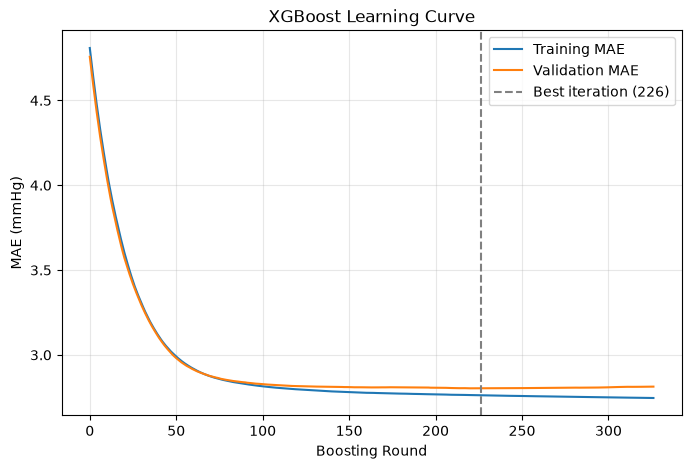

Best iteration: 226
Best validation MAE: 2.8031


In [8]:
curve_model = xgb.XGBRegressor(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=3,
    early_stopping_rounds=100,
    eval_metric="mae",
    random_state=42,
    n_jobs=-1,
)

curve_model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_validation, y_validation)],
    verbose=False,
)

history = curve_model.evals_result()

plt.figure(figsize=(8, 5))

plt.plot(history["validation_0"]["mae"], label="Training MAE")
plt.plot(history["validation_1"]["mae"], label="Validation MAE")

plt.axvline(
    curve_model.best_iteration,
    linestyle="--",
    color="grey",
    label=f"Best iteration ({curve_model.best_iteration})",
)

plt.xlabel("Boosting Round")
plt.ylabel("MAE (mmHg)")
plt.title("XGBoost Learning Curve")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Best iteration:", curve_model.best_iteration)
print(f"Best validation MAE: {min(history['validation_1']['mae']):.4f}")

### What the curve shows

The training and validation lines sit almost exactly on top of each other for the entire run.

In a typical overfitting picture the two separate: training error keeps falling while validation error bottoms out and turns upward. That separation never happens here. Both flatten together around round 100 and stay flat.

Two conclusions follow. The model is **not** overfitting at these settings — and there is **no hidden capacity left to exploit**. Adding trees does nothing in either direction, which means the limit is the data rather than the model.

## Experiment 3: Tree Depth

`max_depth` controls how many feature interactions a single tree can represent. With only two features, deep trees mostly carve the (iCare, CCT) plane into very small boxes, which is a reliable way to overfit.

In [9]:
depth_values = [1, 2, 3, 4, 5, 6, 8, 10]

depth_results = []

for depth in depth_values:

    model = xgb.XGBRegressor(
        n_estimators=5000,
        learning_rate=0.03,
        max_depth=depth,
        early_stopping_rounds=100,
        eval_metric="mae",
        random_state=42,
        n_jobs=-1,
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_validation, y_validation)],
        verbose=False,
    )

    depth_results.append({
        "max_depth": depth,
        "best_iteration": model.best_iteration,
        **evaluate(y_validation, model.predict(X_validation)),
    })

depth_results_df = pd.DataFrame(depth_results)

depth_results_df

,max_depth,best_iteration,MAE,RMSE,R2
0,1,409,2.814305,4.020589,0.672908
1,2,353,2.801585,3.998929,0.676423
2,3,226,2.803051,4.005900,0.675294
3,4,129,2.830459,4.047556,0.668506
4,5,109,2.856757,4.091549,0.661261
5,6,107,2.884538,4.135871,0.653882
6,8,77,2.973724,4.229169,0.638091
7,10,66,3.053406,4.308908,0.624314


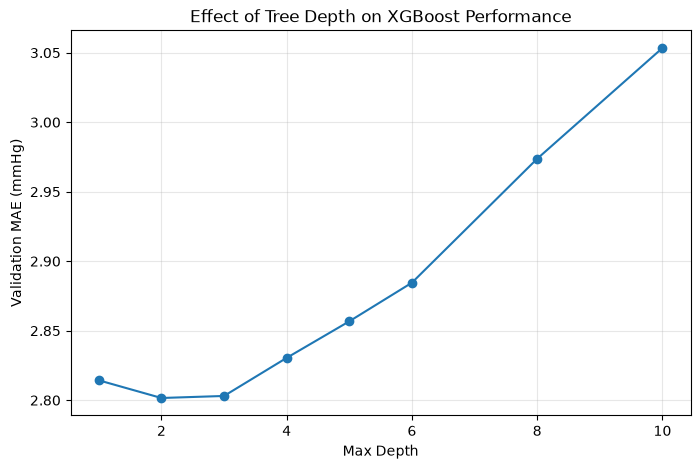

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    depth_results_df["max_depth"],
    depth_results_df["MAE"],
    marker="o",
)

plt.xlabel("Max Depth")
plt.ylabel("Validation MAE (mmHg)")
plt.title("Effect of Tree Depth on XGBoost Performance")

plt.grid(True, alpha=0.3)
plt.show()

### What happened

Best at **depth 2 or 3** (MAE 2.802 and 2.803), and steadily worse from depth 4 onward, reaching 3.053 at depth 10.

Depth controls how many inputs a single tree can combine before making a prediction. With two features there is almost nothing to combine — the useful pattern is close to "pressure rises with iCare", possibly with a bend. A depth-2 tree can express that. A depth-10 tree carves the plane into up to 1,024 boxes, and with 4,648 training rows most of those boxes describe individual patients.

Note also that deeper trees stop earlier (409 trees at depth 1, only 66 at depth 10). Early stopping is compensating: the more each tree overfits, the sooner validation error stops improving.

## Experiment 4: Minimum Child Weight

`min_child_weight` sets the minimum total instance weight required in a leaf. Larger values stop the model from creating leaves supported by only a handful of patients — the direct analogue of `min_samples_leaf` in Random Forest.

In [11]:
child_weight_values = [1, 3, 5, 10, 20, 50, 100]

child_results = []

for weight in child_weight_values:

    model = xgb.XGBRegressor(
        n_estimators=5000,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=weight,
        early_stopping_rounds=100,
        eval_metric="mae",
        random_state=42,
        n_jobs=-1,
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_validation, y_validation)],
        verbose=False,
    )

    child_results.append({
        "min_child_weight": weight,
        "best_iteration": model.best_iteration,
        **evaluate(y_validation, model.predict(X_validation)),
    })

child_results_df = pd.DataFrame(child_results)

child_results_df

,min_child_weight,best_iteration,MAE,RMSE,R2
0,1,226,2.803051,4.005900,0.675294
1,3,205,2.808294,4.009577,0.674698
2,5,197,2.809984,4.013133,0.674120
3,10,173,2.813444,4.010849,0.674491
4,20,204,2.804242,3.992215,0.677509
5,50,180,2.828713,4.060968,0.666305
6,100,161,2.803967,4.004961,0.675446


### What happened

Essentially flat: 2.803 to 2.829 across a hundred-fold change in the setting.

Requiring 100 eyes per leaf gives the same answer as requiring 1. A model that does not care how you constrain it is a model that was never straining against the constraint — the pattern it has found is coarse enough to survive any of these settings.

This is the third experiment in a row pointing the same way, and it is worth naming explicitly: **the signal available from these two inputs is simple, and every reasonable configuration finds all of it.**

## Experiment 5: Randomised Search with Patient-Grouped Cross-Validation

The individual experiments above vary one parameter at a time, which cannot find good *combinations*. We now run a randomised search over the full parameter space: 100 random configurations drawn from nine settings, each scored by 5-fold cross-validation.

**Cross-validation** means repeatedly holding out a fifth of the training data, fitting on the remaining four fifths, and scoring on the held-out part. Each configuration is therefore judged on data it did not learn from, five times over. This keeps the validation set from being worn out by 100 comparisons.

### Why GroupKFold and not plain KFold

This is the one methodological difference from the Random Forest notebook, and it matters.

The Random Forest tuning used `cv=5`, which is an ordinary `KFold`. It shuffles **rows**. Because the left and right eyes of the same patient are two separate rows with strongly correlated IOP, ordinary KFold routinely places `L00220` in the training fold and `R00220` in the held-out fold. The cross-validation score is then measured partly on patients the model has already seen, which makes it optimistically biased.

`GroupKFold(groups=patient_uid)` keeps both eyes of a patient inside the same fold. It is the same rule the train/test split already enforces, applied one level down.

This is the correct method regardless of how much it changes the number, and it matters more the harder a search is pushed. For reference, the grouped score below came out at 2.838, against the 2.850 the Random Forest notebook reported under ordinary KFold — but those two figures are not directly comparable, because they differ in model family as well as in cross-validation scheme. The point of using `GroupKFold` here is that the score it produces is trustworthy, not that it is higher or lower.

In [12]:
param_distributions = {
    "n_estimators": [100, 200, 300, 500, 800, 1200],
    "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5, 6],
    "min_child_weight": [1, 3, 5, 10, 20, 50],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_lambda": [0.1, 1, 5, 10, 50],
    "reg_alpha": [0, 0.1, 1, 5],
    "gamma": [0, 0.1, 1],
}

search = RandomizedSearchCV(
    estimator=xgb.XGBRegressor(random_state=42, n_jobs=1),
    param_distributions=param_distributions,
    n_iter=100,
    scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=5),
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

search.fit(X_train, y_train, groups=train_groups)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.6, 0.8, ...], 'gamma': [0, 0.1, ...], 'learning_rate': [0.01, 0.02, ...], 'max_depth': [2, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",100
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator

In [13]:
print("Best parameters:")
for key, value in sorted(search.best_params_.items()):
    print(f"  {key}: {value}")

print(f"\nBest patient-grouped cross-validation MAE: {-search.best_score_:.4f}")

Best parameters:
  colsample_bytree: 1.0
  gamma: 0
  learning_rate: 0.01
  max_depth: 3
  min_child_weight: 5
  n_estimators: 500
  reg_alpha: 0
  reg_lambda: 10
  subsample: 0.6

Best patient-grouped cross-validation MAE: 2.8383


In [14]:
best_xgb = search.best_estimator_

search_metrics = report(
    "Tuned XGBoost — Validation",
    y_validation,
    best_xgb.predict(X_validation),
)

Tuned XGBoost — Validation
--------------------------
MAE:  2.809 mmHg
RMSE: 4.009 mmHg
R²:   0.675


### What the search chose

Patient-grouped cross-validation MAE **2.838**, validation MAE **2.809**.

The selected configuration is conservative, exactly as the one-at-a-time sweeps predicted: `max_depth=3`, `learning_rate=0.01`, `subsample=0.6`, `reg_lambda=10`. Searching 100 combinations across nine settings improved on the hand-tuned single-parameter result by about 0.006 mmHg.

That is a useful negative result in itself. The sweeps above had already found the plateau; the search confirmed there is no clever combination hiding off the one-dimensional paths.

## Final XGBoost Model

We fix the configuration selected by the search and refit it, so that the rest of the notebook works with a single, explicitly-specified model rather than a search artefact.

In [15]:
final_params = dict(search.best_params_)

final_xgb = xgb.XGBRegressor(
    **final_params,
    random_state=42,
    n_jobs=-1,
)

final_xgb.fit(X_train, y_train)

train_predictions = final_xgb.predict(X_train)
validation_predictions = final_xgb.predict(X_validation)

final_params

{'subsample': 0.6,
 'reg_lambda': 10,
 'reg_alpha': 0,
 'n_estimators': 500,
 'min_child_weight': 5,
 'max_depth': 3,
 'learning_rate': 0.01,
 'gamma': 0,
 'colsample_bytree': 1.0}

## Overfitting Check

We compare training and validation performance for the final model.

A small gap indicates the model is generalising, and that adding complexity is unlikely to help. A large gap indicates memorisation of the training patients.

In [16]:
train_metrics = report("Training", y_train, train_predictions)
print()
validation_metrics = report("Validation", y_validation, validation_predictions)

print(f"\nMAE gap (validation - training): "
      f"{validation_metrics['MAE'] - train_metrics['MAE']:+.3f} mmHg")

Training
--------
MAE:  2.787 mmHg
RMSE: 3.767 mmHg
R²:   0.726

Validation
----------
MAE:  2.809 mmHg
RMSE: 4.009 mmHg
R²:   0.675

MAE gap (validation - training): +0.022 mmHg


### What happened

Training MAE 2.787, validation MAE 2.809 — a gap of **0.022 mmHg**.

Normally this is the number you hope for. It says the model performs on unseen patients almost exactly as it does on the ones it learned from, so nothing here is memorisation.

It also closes off a direction. A large gap would mean "reduce complexity and recover accuracy"; a small gap with mediocre accuracy means the accuracy is not being lost to overfitting, so there is nothing to recover. Whatever is limiting this model is not the model.

## Residual Analysis

A residual is the difference between the actual and the predicted GAT IOP:

Residual = Actual GAT IOP − Predicted GAT IOP

A well-behaved model has residuals scattered randomly around zero with no visible structure. Structure means the model is systematically wrong in some part of the measurement range.

In [17]:
residuals = y_validation - validation_predictions

print("Mean residual:    ", round(residuals.mean(), 4))
print("Std of residuals: ", round(residuals.std(), 4))
print("Minimum residual: ", round(residuals.min(), 4))
print("Maximum residual: ", round(residuals.max(), 4))

Mean residual:     0.156
Std of residuals:  4.0078
Minimum residual:  -19.6677
Maximum residual:  22.9629


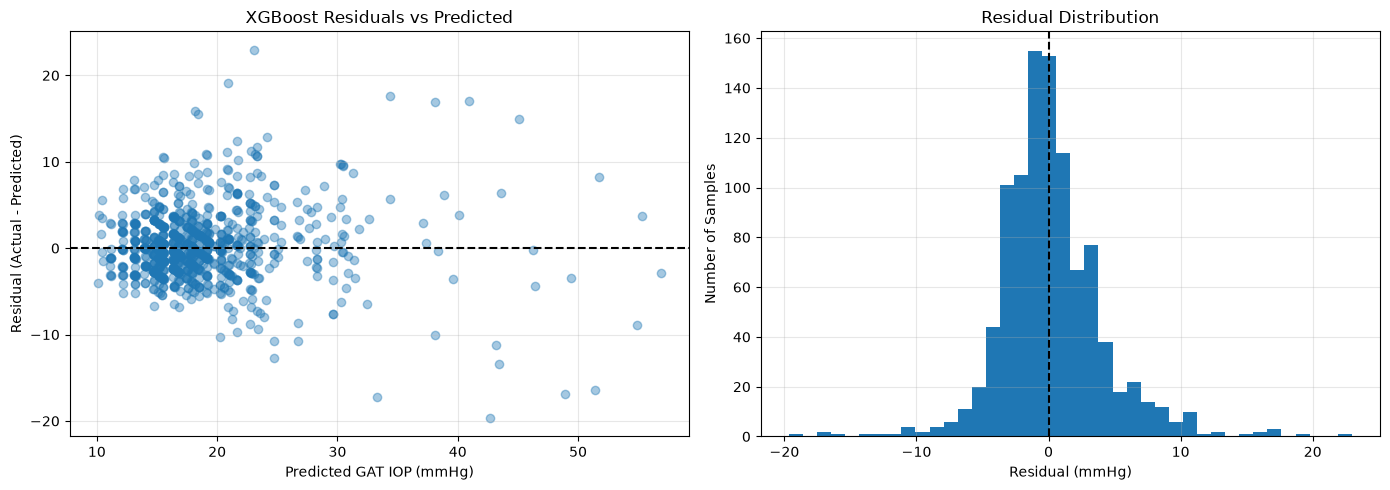

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(validation_predictions, residuals, alpha=0.4)
axes[0].axhline(0, linestyle="--", color="black")
axes[0].set_xlabel("Predicted GAT IOP (mmHg)")
axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].set_title("XGBoost Residuals vs Predicted")
axes[0].grid(True, alpha=0.3)

axes[1].hist(residuals, bins=40)
axes[1].axvline(0, linestyle="--", color="black")
axes[1].set_xlabel("Residual (mmHg)")
axes[1].set_ylabel("Number of Samples")
axes[1].set_title("Residual Distribution")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### What the residuals show

Mean residual **+0.156 mmHg**, so the model is close to unbiased on average, and the histogram is roughly symmetric around zero with no second peak.

The scatter plot is the more informative of the two. The band of points fans outward: narrow at low predicted pressures, much wider at high ones. Errors are not a constant size — they grow with the pressure being predicted.

The extremes are worth noting. The largest residuals are −19.7 and +23.0 mmHg. Those are single eyes where the prediction was wrong by more than the typical eye's entire pressure.

## Actual vs Predicted GAT IOP

A perfect model places every point on the 45° line. The vertical distance of a point from that line is its error.

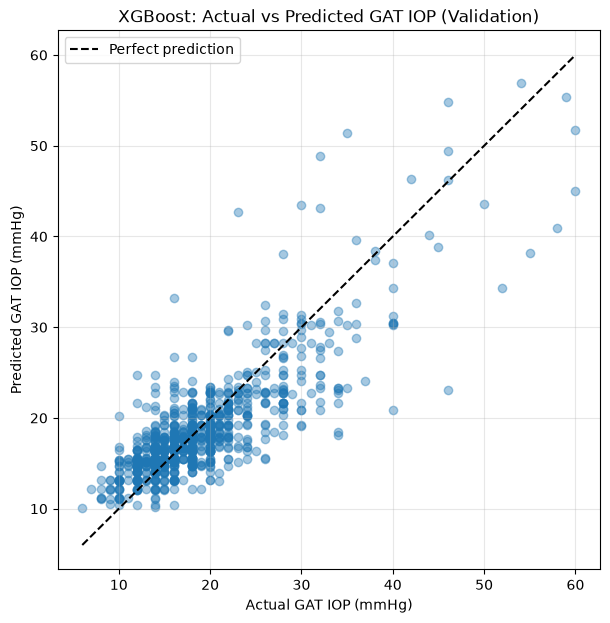

In [19]:
plt.figure(figsize=(7, 7))

plt.scatter(y_validation, validation_predictions, alpha=0.4)

min_iop = min(y_validation.min(), validation_predictions.min())
max_iop = max(y_validation.max(), validation_predictions.max())

plt.plot(
    [min_iop, max_iop],
    [min_iop, max_iop],
    linestyle="--",
    color="black",
    label="Perfect prediction",
)

plt.xlabel("Actual GAT IOP (mmHg)")
plt.ylabel("Predicted GAT IOP (mmHg)")
plt.title("XGBoost: Actual vs Predicted GAT IOP (Validation)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### What this shows

The cloud is tilted relative to the 45-degree line rather than lying along it.

At the low end, points sit above the line — the model predicts higher than the truth. At the high end they sit below it — the model predicts lower. The predictions are **compressed toward the middle** of the range.

This is regression to the mean, and it is what a model trained to minimise average error will always do when one region of the target dominates the data. It is quantified in the error-by-range table further down.

## Bland–Altman Analysis

Bland–Altman is the standard way to compare two clinical measurement methods. Instead of asking "are they correlated", it asks "how far apart are they, and does the disagreement depend on the magnitude of the measurement".

For each eye we plot:

- **x-axis:** the mean of the actual and predicted GAT IOP
- **y-axis:** the difference between them

The **bias** is the mean difference — a systematic over- or under-estimate. The **limits of agreement** are bias ± 1.96 × SD, and they bracket roughly 95% of the disagreements. These limits are the number a clinician actually cares about: they say how wrong a single prediction can plausibly be.

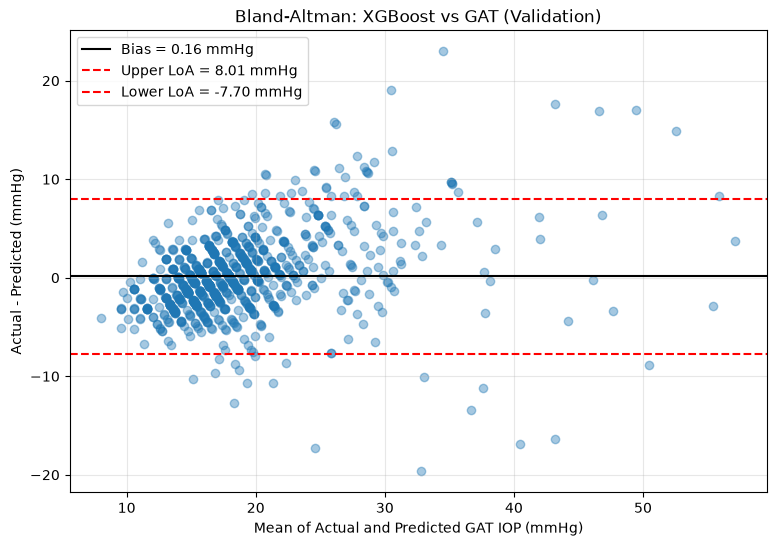

Bias:                  0.156 mmHg
Limits of agreement:   -7.699 to 8.011 mmHg
Within +/- 2 mmHg:     48.9% of eyes
Within +/- 3 mmHg:     66.2% of eyes
Within +/- 5 mmHg:     86.1% of eyes


In [20]:
mean_values = (y_validation + validation_predictions) / 2
differences = y_validation - validation_predictions

bias = differences.mean()
sd = differences.std()

upper_limit = bias + 1.96 * sd
lower_limit = bias - 1.96 * sd

plt.figure(figsize=(9, 6))

plt.scatter(mean_values, differences, alpha=0.4)

plt.axhline(bias, color="black",
            label=f"Bias = {bias:.2f} mmHg")
plt.axhline(upper_limit, color="red", linestyle="--",
            label=f"Upper LoA = {upper_limit:.2f} mmHg")
plt.axhline(lower_limit, color="red", linestyle="--",
            label=f"Lower LoA = {lower_limit:.2f} mmHg")

plt.xlabel("Mean of Actual and Predicted GAT IOP (mmHg)")
plt.ylabel("Actual - Predicted (mmHg)")
plt.title("Bland-Altman: XGBoost vs GAT (Validation)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Bias:                  {bias:.3f} mmHg")
print(f"Limits of agreement:   {lower_limit:.3f} to {upper_limit:.3f} mmHg")
print(f"Within +/- 2 mmHg:     "
      f"{(differences.abs() <= 2).mean() * 100:.1f}% of eyes")
print(f"Within +/- 3 mmHg:     "
      f"{(differences.abs() <= 3).mean() * 100:.1f}% of eyes")
print(f"Within +/- 5 mmHg:     "
      f"{(differences.abs() <= 5).mean() * 100:.1f}% of eyes")

### What this means clinically

**Bias +0.156 mmHg.** On average the model neither over- nor under-estimates. This is the good part of the result.

**Limits of agreement −7.70 to +8.01 mmHg.** This is the part that matters. It says that for an individual eye, the prediction can reasonably be 8 mmHg away from what GAT would have measured — and 8 mmHg is the difference between a normal reading and one that would prompt treatment.

Put in terms of eyes rather than intervals: **48.9% land within ±2 mmHg, 66.2% within ±3, 86.1% within ±5.** Roughly one eye in three is more than 3 mmHg out.

A small bias with wide limits is a specific kind of result. It means the model is right on average and unreliable individually — which is fine for describing a population and not sufficient for deciding about a patient.

## Error by IOP Range

Overall MAE averages over the whole dataset, and the dataset is dominated by eyes in the 10–20 mmHg range. That hides how the model behaves at the high pressures that matter clinically.

We break the validation errors down by actual GAT IOP range, and include the identity baseline in the same table so the comparison is meaningful at every level.

In [21]:
iop_ranges = [
    ("<10", y_validation < 10),
    ("10-20", (y_validation >= 10) & (y_validation < 20)),
    ("20-30", (y_validation >= 20) & (y_validation < 30)),
    ("30-40", (y_validation >= 30) & (y_validation < 40)),
    ("40+", y_validation >= 40),
]

range_results = []

for name, mask in iop_ranges:

    if mask.sum() == 0:
        continue

    actual = y_validation[mask]
    predicted = validation_predictions[mask]
    icare_raw = X_validation.loc[mask, "icare_iop"]

    range_results.append({
        "IOP Range": name,
        "Samples": int(mask.sum()),
        "XGB MAE": mean_absolute_error(actual, predicted),
        "XGB RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Identity MAE": mean_absolute_error(actual, icare_raw),
        "Mean Residual": (actual - predicted).mean(),
    })

range_results_df = pd.DataFrame(range_results)

range_results_df

,IOP Range,Samples,XGB MAE,XGB RMSE,Identity MAE,Mean Residual
0,<10,15,3.728006,3.935815,1.000000,-3.728006
1,10-20,641,2.090146,2.802508,2.457098,-1.181282
2,20-30,267,3.113239,4.024033,3.303371,2.075527
3,30-40,55,6.761849,8.216075,5.909091,4.401321
4,40+,23,9.242723,11.001029,8.782609,7.524378


### The most important table in this notebook

Read the `XGB MAE` and `Identity MAE` columns side by side.

**In the 10–20 band** — 641 of 1,001 eyes — the model does its job: 2.09 against the baseline's 2.46.

**Above 30 mmHg the model is worse than doing nothing.** At 30–40 it scores 6.76 against the baseline's 5.91; at 40+, 9.24 against 8.78. Tuning produced a model that is beaten by reading the raw iCare number in exactly the range where an error changes management.

**The mean residual column explains why.** It is strongly positive at the top (+4.40 and +7.52), meaning actual pressure was far higher than predicted — the model **systematically under-predicts high pressure**. It is negative at the bottom (−3.73 in the under-10 band), meaning it over-predicts there.

The cause is the training distribution: about 93% of training eyes sit below 30 mmHg. A model minimising average error learns that guessing near the middle is a good bet, because it usually is. The arithmetic is sound and the clinical behaviour is wrong — under-calling high pressure is the one direction in which being wrong is costly.

Any future work on this dataset should be judged on this table rather than on the overall MAE.

## Feature Importance

With only two features this is less about discovery and more about confirming what the model is actually using.

We report two views:

- **Gain importance** — how much each feature reduced the loss across all splits it was used in. This is internal to the tree structure.
- **Permutation importance** — how much validation MAE degrades when a feature's values are randomly shuffled. This measures the feature's real predictive contribution on held-out data, and is the more trustworthy of the two.

In [22]:
booster_scores = final_xgb.get_booster().get_score(importance_type="gain")

gain_importance = pd.DataFrame([
    {"Feature": f, "Gain": booster_scores.get(f, 0.0)}
    for f in features
])

perm = permutation_importance(
    final_xgb,
    X_validation,
    y_validation,
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=42,
    n_jobs=-1,
)

importance_df = gain_importance.assign(**{
    "Permutation (MAE increase)": perm.importances_mean,
    "Permutation SD": perm.importances_std,
})

importance_df

,Feature,Gain,Permutation (MAE increase),Permutation SD
0,icare_iop,2583.259033,3.423322,0.110135
1,cct,79.635757,0.007079,0.009967


### What happened

Permutation importance is the column to read, because it measures the effect on held-out predictions rather than on the tree structure.

**Shuffling iCare costs 3.423 mmHg of MAE. Shuffling CCT costs 0.007 ± 0.010.**

CCT's measured effect is smaller than its own run-to-run variation across 30 repeats. In other words it cannot be distinguished from zero. The model is, in practice, using one input.

The gain column shows CCT is not entirely ignored inside the trees (79.6 against iCare's 2,583) — the model does split on it. Those splits simply do not improve predictions on eyes it has not seen, which is what makes permutation importance the more trustworthy of the two measures.

### Does CCT contribute anything?

The clinical premise of this project is that CCT corrects the iCare reading. We can test that premise directly: train the identical model on iCare alone and compare.

If the two-feature model is not meaningfully better than the one-feature model, then within this dataset and this CCT range, CCT is not carrying usable signal.

In [23]:
xgb_icare_only = xgb.XGBRegressor(
    **final_params,
    random_state=42,
    n_jobs=-1,
)

xgb_icare_only.fit(X_train[["icare_iop"]], y_train)

ablation_df = pd.DataFrame([
    {
        "Features": "iCare + CCT",
        **evaluate(y_validation, final_xgb.predict(X_validation)),
    },
    {
        "Features": "iCare only",
        **evaluate(
            y_validation,
            xgb_icare_only.predict(X_validation[["icare_iop"]]),
        ),
    },
])

ablation_df

,Features,MAE,RMSE,R2
0,iCare + CCT,2.808614,4.008798,0.674824
1,iCare only,2.807960,4.013839,0.674006


### The result, and what it probably means

**Dropping CCT entirely makes the model fractionally better** — 2.8080 against 2.8086.

The difference is far too small to mean "CCT hurts". What it does rule out is CCT helping. Combined with the permutation result above and the linear baselines near the top of the notebook, three independent tests agree: within this dataset, corneal thickness carries no usable signal for correcting iCare toward GAT.

#### Why this is most likely an artefact of the cleaning pipeline

This result contradicts the clinical literature, which is a reason to look at the data before accepting it.

`src/clean_ranges.py` restricts CCT to **480–580 µm**. But CCT's effect on tonometry is concentrated at the extremes — thin corneas deform easily and read low, thick corneas resist and read high. The 480–580 window keeps the middle of the distribution and discards precisely the eyes where CCT would do visible work.

Within the surviving window the fitted effect is about 0.01 mmHg per µm, so the full 100 µm span moves the prediction by roughly 1 mmHg — smaller than the residual scatter the model is already fighting.

**This is testable, and it should be the next experiment:** rerun the pipeline with a wider CCT range and repeat this ablation. If CCT starts contributing, the filter was removing the signal. If it still does not, that is a genuine finding about rebound tonometry in this population, and worth reporting as one.

## Final Test Evaluation

The XGBoost model has now been selected using the training and validation sets only. The test set has not influenced any decision in this notebook.

We evaluate it once, here.

In [24]:
test_predictions = final_xgb.predict(X_test)

test_metrics = report(
    "Final XGBoost — Test",
    y_test,
    test_predictions,
)

Final XGBoost — Test
--------------------
MAE:  2.901 mmHg
RMSE: 3.986 mmHg
R²:   0.730


In [25]:
test_differences = y_test - test_predictions

test_bias = test_differences.mean()
test_sd = test_differences.std()

print("Test set Bland-Altman")
print("---------------------")
print(f"Bias:                {test_bias:.3f} mmHg")
print(f"Limits of agreement: "
      f"{test_bias - 1.96 * test_sd:.3f} to "
      f"{test_bias + 1.96 * test_sd:.3f} mmHg")
print(f"Within +/- 2 mmHg:   {(test_differences.abs() <= 2).mean() * 100:.1f}%")
print(f"Within +/- 3 mmHg:   {(test_differences.abs() <= 3).mean() * 100:.1f}%")
print(f"Within +/- 5 mmHg:   {(test_differences.abs() <= 5).mean() * 100:.1f}%")

Test set Bland-Altman
---------------------
Bias:                0.374 mmHg
Limits of agreement: -7.407 to 8.155 mmHg
Within +/- 2 mmHg:   47.0%
Within +/- 3 mmHg:   64.0%
Within +/- 5 mmHg:   84.0%


### Final result

**Test MAE 2.901 mmHg, RMSE 3.986, R² 0.730.**

Against the references computed at the top of the notebook on the same test set: identity 3.214, linear on iCare alone 3.005. The tuned model improves on the straight line by **0.104 mmHg**, about 3%.

The test Bland–Altman limits are −7.41 to +8.16 mmHg, with 47.0% of eyes within ±2. These track the validation figures closely, which at least confirms the validation set was not being quietly overfitted during tuning.

For scale: GAT itself is read to the nearest 0.5–1 mmHg, and two trained clinicians measuring the same eye typically differ by around 2 mmHg. The improvement this model delivers over a straight line sits inside the noise of the reference measurement.

## Model Comparison

Finally we place XGBoost alongside the Random Forest and the non-ML baselines, evaluated identically on both validation and test.

The Random Forest is refitted here with the configuration selected in `random_forest.ipynb` (`n_estimators=100`, `max_depth=4`), so that all numbers in this table come from the same machine and the same data.

The ANN row is quoted from `02_ann.ipynb`; it is not refitted here because that notebook requires PyTorch. The ANN was never evaluated on the test set.

In [26]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=4,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1,
)

rf_model.fit(X_train, y_train)

comparison_rows = []


def add_row(name, val_pred, test_pred):
    val = evaluate(y_validation, val_pred)
    tst = evaluate(y_test, test_pred) if test_pred is not None else {}
    comparison_rows.append({
        "Model": name,
        "Val MAE": val["MAE"],
        "Val RMSE": val["RMSE"],
        "Val R2": val["R2"],
        "Test MAE": tst.get("MAE", np.nan),
        "Test RMSE": tst.get("RMSE", np.nan),
        "Test R2": tst.get("R2", np.nan),
    })


add_row(
    "Identity (GAT = iCare)",
    X_validation["icare_iop"],
    X_test["icare_iop"],
)
add_row(
    "Linear (iCare only)",
    lin_icare.predict(X_validation[["icare_iop"]]),
    lin_icare.predict(X_test[["icare_iop"]]),
)
add_row(
    "Linear (iCare + CCT)",
    lin_both.predict(X_validation),
    lin_both.predict(X_test),
)
add_row(
    "Random Forest (depth 4)",
    rf_model.predict(X_validation),
    rf_model.predict(X_test),
)
add_row(
    "XGBoost (tuned)",
    validation_predictions,
    test_predictions,
)

comparison_df = pd.DataFrame(comparison_rows)

# ANN result quoted from 02_ann.ipynb (not refitted here)
comparison_df.loc[len(comparison_df)] = {
    "Model": "ANN 2-32-16-1 (quoted)",
    "Val MAE": 2.847,
    "Val RMSE": 4.007,
    "Val R2": 0.675,
    "Test MAE": np.nan,
    "Test RMSE": np.nan,
    "Test R2": np.nan,
}

comparison_df.round(3)

,Model,Val MAE,Val RMSE,Val R2,Test MAE,Test RMSE,Test R2
0,Identity (GAT = iCare),2.996,4.258,0.633,3.214,4.352,0.678
1,Linear (iCare only),2.883,4.043,0.669,3.005,4.114,0.712
2,Linear (iCare + CCT),2.892,4.042,0.669,3.002,4.113,0.713
3,Random Forest (depth 4),2.806,4.017,0.673,2.920,4.000,0.728
4,XGBoost (tuned),2.809,4.009,0.675,2.901,3.986,0.730
5,ANN 2-32-16-1 (quoted),2.847,4.007,0.675,NaN,NaN,NaN


## What the comparison table says

Three things, in order of importance.

**1. Every model lands in the same place.** Random Forest 2.806, XGBoost 2.809, the neural network 2.847 — all on validation, spread 0.04 mmHg. These methods share no assumptions: one averages independent trees, one stacks sequential corrections, one fits a smooth weighted function. They fail in different ways and for different reasons. When they converge this tightly, the limit is the **information in the data**, not the choice of algorithm. Trying a fourth model family is not a promising use of time.

**2. The gain over a straight line is 0.10 mmHg.** Test MAE goes from 3.005 to 2.901. The tuning in this notebook was worth doing — it is a real improvement, reproducibly measured on held-out patients — but it is not a clinically meaningful one.

**3. R² and MAE tell different stories about the same predictions.** R² rises from 0.678 to 0.730 across the table, which reads as solid. MAE moves from 3.214 to 2.901 on measurements in the teens and twenties, which reads as modest. R² is generous here because it measures against a very weak alternative: always guessing the mean pressure, which scores MAE 5.12. Trust the MAE, and trust the limits of agreement above it.

## Save Model and Metrics

The final model and the metrics table are written out so later work does not have to refit anything.

In [27]:
from pathlib import Path

Path("../models").mkdir(parents=True, exist_ok=True)
Path("../results/metrics").mkdir(parents=True, exist_ok=True)

final_xgb.save_model("../models/xgboost_iop.json")

comparison_df.to_csv(
    "../results/metrics/model_comparison.csv",
    index=False,
)

range_results_df.to_csv(
    "../results/metrics/xgboost_error_by_iop_range.csv",
    index=False,
)

print("Saved:")
print("  models/xgboost_iop.json")
print("  results/metrics/model_comparison.csv")
print("  results/metrics/xgboost_error_by_iop_range.csv")

Saved:
  models/xgboost_iop.json
  results/metrics/model_comparison.csv
  results/metrics/xgboost_error_by_iop_range.csv


## Conclusions

**What was built.** A tuned XGBoost model predicting GAT IOP from iCare IOP and CCT, selected using patient-grouped cross-validation and evaluated once on a held-out test set. Test MAE 2.901 mmHg, RMSE 3.986, R² 0.730 — the best result in this project.

**What it is worth.** Roughly 0.10 mmHg over a two-parameter straight line, and 0.31 mmHg over reading the iCare device unchanged. The limits of agreement against GAT are −7.41 to +8.16 mmHg.

**What was learned along the way**, which matters more than the headline number:

1. **CCT contributes nothing measurable** in this dataset — confirmed by permutation importance, by ablation, and by the linear baselines. The 480–580 µm filter in the cleaning pipeline is the most likely explanation and is testable.
2. **The model is worse than the identity baseline above 30 mmHg**, and systematically under-predicts high pressure, because 93% of training eyes sit below 30.
3. **Random Forest, XGBoost and the ANN agree within 0.04 mmHg.** The ceiling here is the data, not the modelling.

### Suggested next steps

1. **Widen or remove the CCT range filter and repeat the ablation.** Highest value by a distance: it tests the project's own premise, and either outcome is informative.
2. **Keep repeat measurements per eye.** `remove_repeated_euid.py` currently discards about 36% of rows. Patient-level splitting already handles the correlation safely, and the extra data would most help the sparse high-pressure region.
3. **Address the high-pressure bias directly** — sample weighting, a log-transformed target, or `monotone_constraints` to force predictions to rise with iCare. This will slightly worsen overall MAE while improving behaviour where it matters; that trade is a clinical judgement, not a technical one.
4. **Add input features.** Two inputs have now been exhausted by three algorithms. Age, sex, corneal hysteresis, curvature and axial length are the plausible candidates.